## Exercise 3 - Regularisation and Generalisation

This exercise investigates the effects of regularisation techniques on model performance and generalisation using the CIFAR-10 dataset. Dropout and data augmentation are evaluated individually and together to examine their impact on overfitting and model performance.

**Experimental Setup**
- Models - MLP and CNN.
- Techniques - Baseline, Dropout (p=0.5), Data Augmentation, and a combination of both.
- Training - 30 epochs, Adam optimiser, learning rate of 0.001, batch size of 128.
- Evaluation - Three random seeds, with training, validation and test accuracy and generalisation gaps.

**1. Importing Libraries and Setting Up the Environment**

In [ ]:
import os, time, copy, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

# Setting the main training parameters
EPOCHS = 30
LR = 1e-3
BATCH_SIZE = 128
NUM_WORKERS = 2
ROOT = "./data"
os.makedirs("figures", exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available()
                      else "mps" if torch.backends.mps.is_available() else "cpu")
print("Using device:", DEVICE)

def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

Using device: cuda


**2. Loading the CIFAR-10 Dataset and Preparing Data Loaders**

In [ ]:
CLASSES = ["aeroplane","automobile","bird","cat","deer","dog","frog","horse","ship","truck"]
MEAN, STD = (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616) # CIFAR-10 normalization values

# Preparing the transformations used for evaluation and training
eval_tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

# Applying light augmentation to make the training images more varied
aug_tf = transforms.Compose([
    transforms.RandomAffine(degrees=10, translate=(0.1, 0.1)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

train_eval_full = datasets.CIFAR10(ROOT, train=True,  download=True,  transform=eval_tf)
train_aug_full  = datasets.CIFAR10(ROOT, train=True,  download=False, transform=aug_tf)
test_set        = datasets.CIFAR10(ROOT, train=False, download=True,  transform=eval_tf)


perm = torch.randperm(50000, generator=torch.Generator().manual_seed(42)).tolist()
train_idx, val_idx = perm[:45000], perm[45000:]
print(f"train={len(train_idx)}  val={len(val_idx)}  test={len(test_set)}")

def make_loaders(augment=False, seed=0):
# Using augmented images only when augmentation is enabled
    g = torch.Generator().manual_seed(seed)
    src = train_aug_full if augment else train_eval_full
    train_loader = DataLoader(Subset(src, train_idx), batch_size=BATCH_SIZE, shuffle=True,
                              num_workers=NUM_WORKERS, generator=g)
    clean_train = DataLoader(Subset(train_eval_full, train_idx), batch_size=512, num_workers=NUM_WORKERS)
    val_loader  = DataLoader(Subset(train_eval_full, val_idx),   batch_size=512, num_workers=NUM_WORKERS)
    test_loader = DataLoader(test_set, batch_size=512, num_workers=NUM_WORKERS)
    return train_loader, clean_train, val_loader, test_loader

100%|██████████| 170M/170M [34:11<00:00, 83.1kB/s]


train=45000  val=5000  test=10000


**3. Model Evaluation Functions**

In [ ]:
# Count the number of trainable parameters in a model
def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


# Run one epoch and calculate the average loss and accuracy
def run_epoch(model, loader, optimizer=None):
    train = optimizer is not None
    model.train(train)
    tot_loss = tot_correct = n = 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            out = model(x)
            loss = F.cross_entropy(out, y)
            if train:
                optimizer.zero_grad(); loss.backward(); optimizer.step()
            tot_loss += loss.item() * len(y)
            tot_correct += (out.argmax(1) == y).sum().item()
            n += len(y)
    return tot_loss / n, tot_correct / n

**4. Model Training and Validation**

In [ ]:
def train_model(model, loaders, epochs=EPOCHS, lr=LR, verbose=True):
    # Using Adam and cross-entropy loss to train the model
    train_loader, clean_train, val_loader, test_loader = loaders
    model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = {k: [] for k in ["train_loss", "val_loss", "train_acc", "val_acc"]}
    best_val, best_state, best_epoch, t0 = -1, None, 0, time.time()

    for ep in range(1, epochs + 1):
        tl, ta = run_epoch(model, train_loader, opt)
        vl, va = run_epoch(model, val_loader)

        for k, v in zip(hist, [tl, vl, ta, va]): hist[k].append(v)

        # Keeping the model from the epoch with the highest validation accuracy
        if va > best_val:
            best_val, best_epoch, best_state = va, ep, copy.deepcopy(model.state_dict())

        if verbose and (ep % 5 == 0 or ep == 1):
            print(f"ep {ep:02d} | train loss {tl:.3f} acc {ta:.3f} | val loss {vl:.3f} acc {va:.3f}")

    # Restoring the best model before evaluating
    model.load_state_dict(best_state)
    ctl, cta = run_epoch(model, clean_train)
    vl, va = run_epoch(model, val_loader)
    tel, tea = run_epoch(model, test_loader)

    res = dict(params=count_params(model), best_epoch=best_epoch, train_loss=ctl, train_acc=cta,
               val_loss=vl, val_acc=va, test_loss=tel, test_acc=tea, gap=cta - tea,
               final_epoch_train_loss=hist["train_loss"][-1], time_s=time.time() - t0)
    return hist, res

**5. Performance Visualization and Confusion Matrix**

In [ ]:
# Plot training and validation loss and accuracy across epochs
def plot_history(hist, title, fname=None):
    ep = range(1, len(hist["train_loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
    ax[0].plot(ep, hist["train_loss"], label="Training"); ax[0].plot(ep, hist["val_loss"], label="Validation")
    ax[0].set(title=f"{title}: loss", xlabel="Epoch", ylabel="Cross-entropy loss"); ax[0].legend(); ax[0].grid(alpha=.3)
    ax[1].plot(ep, hist["train_acc"], label="Training"); ax[1].plot(ep, hist["val_acc"], label="Validation")
    ax[1].set(title=f"{title}: accuracy", xlabel="Epoch", ylabel="Accuracy"); ax[1].legend(); ax[1].grid(alpha=.3)
    plt.tight_layout()
    if fname: plt.savefig(f"figures/{fname}.png", dpi=200)
    plt.show()


# confusion matrix from predictions
@torch.no_grad()
def confusion(model, loader):
    model.eval(); cm = np.zeros((10, 10), dtype=int)
    for x, y in loader:
        p = model(x.to(DEVICE)).argmax(1).cpu().numpy()
        for t, q in zip(y.numpy(), p): cm[t, q] += 1
    return cm



def plot_confusion(cm, title, fname=None):
    plt.figure(figsize=(6.2, 5.4)); plt.imshow(cm, cmap="Blues"); plt.colorbar()
    plt.xticks(range(10), CLASSES, rotation=60, ha="right"); plt.yticks(range(10), CLASSES)
    for i in range(10):
        for j in range(10):
            plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=6,
                     color="white" if cm[i, j] > cm.max() / 2 else "black")
    plt.title(title); plt.xlabel("Predicted"); plt.ylabel("True"); plt.tight_layout()
    if fname: plt.savefig(f"figures/{fname}.png", dpi=200)
    plt.show()

**6. The MLP and CNN Architectures**

In [ ]:
# Defining a simple MLP
class MLP(nn.Module):
    # Three trainable layers
    def __init__(self, h1=512, h2=256):
        super().__init__()
        self.net = nn.Sequential(nn.Flatten(), nn.Linear(3 * 32 * 32, h1), nn.ReLU(),
                                 nn.Linear(h1, h2), nn.ReLU(), nn.Linear(h2, 10))

    def forward(self, x):
        return self.net(x)  # Return raw predictions (logits)


# Building a CNN with configurable channels and dropout
def build_cnn(channels, dropout=0.0, max_pools=3, n_classes=10):
    # Addding convolution, activation and pooling layer
    layers, c = [], 3
    for i, ch in enumerate(channels):
        layers += [nn.Conv2d(c, ch, 3, padding=1), nn.ReLU()]
        if i < max_pools: layers.append(nn.MaxPool2d(2))
        c = ch

    layers.append(nn.Flatten())

    # Calculating the flattened feature size before adding the final layer
    with torch.no_grad():
        d = nn.Sequential(*layers)(torch.zeros(1, 3, 32, 32)).shape[1]

    if dropout > 0:
        layers.append(nn.Dropout(dropout))

    layers.append(nn.Linear(d, n_classes))
    return nn.Sequential(*layers)

**7. Running Experiments Across Different Configurations and Seeds**

In [ ]:
import json

SEEDS = [0, 1, 2]

# Defining the configurations
CONFIGS = {
    "Baseline":           dict(dropout=0.0, augment=False),
    "Dropout (p=0.5)":    dict(dropout=0.5, augment=False),
    "Augmentation":       dict(dropout=0.0, augment=True),
    "Dropout + Augment.": dict(dropout=0.5, augment=True),
}

# Saving progress after each run
CKPT = "ex3_checkpoint.json"
rows, hists = [], {}


if os.path.exists(CKPT):
    saved = json.load(open(CKPT))
    rows = saved["rows"]
    hists = {(k.rsplit("||", 1)[0], int(k.rsplit("||", 1)[1])): v for k, v in saved["hists"].items()}
    print(f"Resuming: {len(rows)} runs already finished")

done = {(r["config"], r["seed"]) for r in rows}

# Training each config using the selected random seeds
for name, cfg in CONFIGS.items():
    for s in SEEDS:
        if (name, s) in done:
            print(f"{name:20s} seed {s}: already done, skipping")
            continue

        set_seed(s)
        loaders = make_loaders(augment=cfg["augment"], seed=s)
        model = build_cnn([32, 64], dropout=cfg["dropout"])

        h, r = train_model(model, loaders, verbose=False)

        # Storing the results and training history for each run
        rows.append(dict(config=name, seed=s, **r))
        hists[(name, s)] = h

        # Updating the checkpoint after every completed run
        json.dump({"rows": rows, "hists": {f"{k[0]}||{k[1]}": v for k, v in hists.items()}}, open(CKPT, "w"))

        print(f"{name:20s} seed {s}: train {r['train_acc']:.3f} val {r['val_acc']:.3f} test {r['test_acc']:.3f} gap {r['gap']:.3f}"
              f" | {r['time_s']/60:.1f} min")

# Save results in a CSV file
raw = pd.DataFrame(rows)
raw.to_csv("ex3_raw_results.csv", index=False)

Baseline             seed 0: train 0.862 val 0.715 test 0.716 gap 0.146 | 5.9 min
Baseline             seed 1: train 0.848 val 0.712 test 0.709 gap 0.139 | 6.0 min
Baseline             seed 2: train 0.841 val 0.719 test 0.716 gap 0.125 | 5.8 min
Dropout (p=0.5)      seed 0: train 0.860 val 0.764 test 0.755 gap 0.105 | 5.8 min
Dropout (p=0.5)      seed 1: train 0.848 val 0.753 test 0.752 gap 0.097 | 5.8 min
Dropout (p=0.5)      seed 2: train 0.866 val 0.757 test 0.763 gap 0.103 | 5.8 min
Augmentation         seed 0: train 0.792 val 0.761 test 0.765 gap 0.027 | 8.6 min
Augmentation         seed 1: train 0.798 val 0.764 test 0.770 gap 0.028 | 8.5 min
Augmentation         seed 2: train 0.791 val 0.764 test 0.762 gap 0.028 | 8.6 min
Dropout + Augment.   seed 0: train 0.773 val 0.748 test 0.755 gap 0.018 | 8.4 min
Dropout + Augment.   seed 1: train 0.768 val 0.749 test 0.752 gap 0.016 | 8.3 min
Dropout + Augment.   seed 2: train 0.769 val 0.751 test 0.749 gap 0.020 | 8.5 min


**8. Experiment result summary comparative table**

In [ ]:
# Calculating the mean and standard deviation for each config
def ms(c):
    return raw.groupby("config", sort=False)[c].agg(lambda x: f"{x.mean()*100:.2f} +/- {x.std()*100:.2f}")

summary = pd.DataFrame({
    "Train acc (%)": ms("train_acc"),
    "Val acc (%)": ms("val_acc"),
    "Test acc (%)": ms("test_acc"),
    "Train-Test gap (pp)": ms("gap")
})

display(summary)
summary.to_csv("ex3_summary.csv")

,Train acc (%),Val acc (%),Test acc (%),Train-Test gap (pp)
config,,,,
Baseline,85.03 +/- 1.04,71.53 +/- 0.32,71.34 +/- 0.40,13.69 +/- 1.06
Dropout (p=0.5),85.82 +/- 0.91,75.79 +/- 0.58,75.65 +/- 0.56,10.17 +/- 0.45
Augmentation,79.38 +/- 0.38,76.31 +/- 0.16,76.60 +/- 0.40,2.78 +/- 0.06
Dropout + Augment.,76.97 +/- 0.25,74.91 +/- 0.15,75.20 +/- 0.29,1.77 +/- 0.22


**9. Comparing Model Performance Across Configurations**

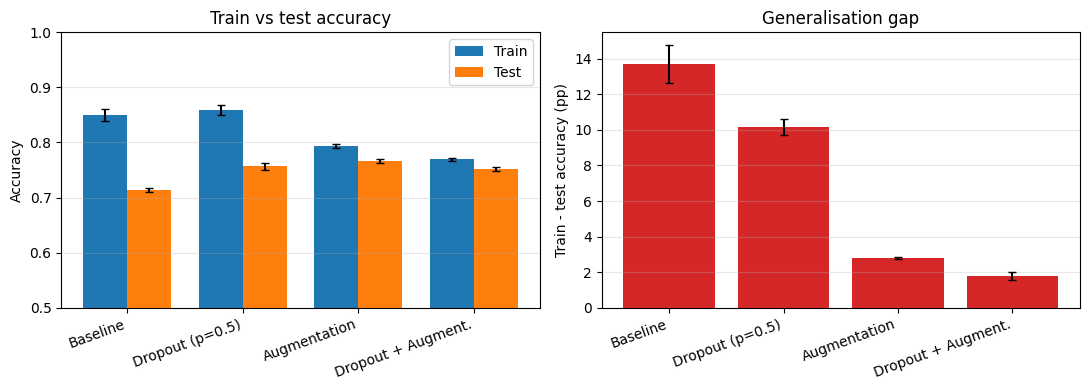

In [ ]:
# Comparing training accuracy, test accuracy and generalisation gap
g = raw.groupby("config", sort=False)[["train_acc", "test_acc", "gap"]].agg(["mean", "std"])

x = np.arange(len(g))
w = 0.38

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

# Comparing training and test accuracy
ax[0].bar(x - w/2, g[("train_acc", "mean")], w, yerr=g[("train_acc", "std")], label="Train", capsize=3)
ax[0].bar(x + w/2, g[("test_acc", "mean")], w, yerr=g[("test_acc", "std")], label="Test", capsize=3)
ax[0].set_xticks(x)
ax[0].set_xticklabels(g.index, rotation=20, ha="right")
ax[0].set_ylim(0.5, 1.0)
ax[0].set(ylabel="Accuracy", title="Train vs test accuracy")
ax[0].legend()
ax[0].grid(axis="y", alpha=.3)

# Comparing the generalisation gap between configs
ax[1].bar(x, g[("gap", "mean")] * 100, yerr=g[("gap", "std")] * 100, capsize=3, color="tab:red")
ax[1].set_xticks(x)
ax[1].set_xticklabels(g.index, rotation=20, ha="right")
ax[1].set(ylabel="Train - test accuracy (pp)", title="Generalisation gap")
ax[1].grid(axis="y", alpha=.3)

plt.tight_layout()
plt.savefig("figures/ex3_comparison.png", dpi=200)
plt.show()

**10. Comparing Training and Validation Loss Curves**

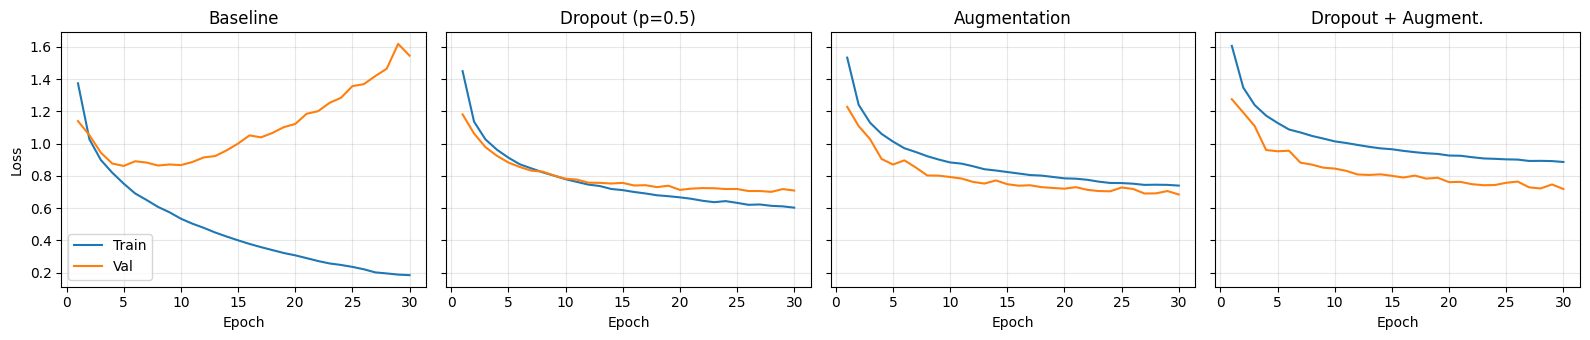

In [ ]:
# Comparing how training and validation loss change across configs
fig, ax = plt.subplots(1, 4, figsize=(16, 3.5), sharey=True)

for a, name in zip(ax, CONFIGS):
    h = hists[(name, 0)]
    e = range(1, EPOCHS + 1)

    a.plot(e, h["train_loss"], label="Train")
    a.plot(e, h["val_loss"], label="Val")
    a.set(title=name, xlabel="Epoch")
    a.grid(alpha=.3)

ax[0].set_ylabel("Loss")
ax[0].legend()

plt.tight_layout()
plt.savefig("figures/ex3_loss_curves.png", dpi=200)
plt.show()